In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Input, SimpleRNN, GRU, LSTM, Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD, Adam

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the data
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
print("x_train.shape:", x_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train.shape: (60000, 28, 28)


In [3]:
# Defining the model
i = Input(shape=x_train[0].shape)
x = LSTM(128)(i)
x = Dense(10, activation='softmax')(x)

model = Model(i, x)

In [4]:
# Compile and train
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
r = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 71s 35ms/step - accuracy: 0.8910 - loss: 0.3384 - val_accuracy: 0.9681 - val_loss: 0.1049
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.9688 - loss: 0.1037 - val_accuracy: 0.9736 - val_loss: 0.0823
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 35ms/step - accuracy: 0.9785 - loss: 0.0718 - val_accuracy: 0.9827 - val_loss: 0.0565
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.9832 - loss: 0.0547 - val_accuracy: 0.9831 - val_loss: 0.0551
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.9862 - loss: 0.0447 - val_accuracy: 0.9865 - val_loss: 0.0458
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 35ms/step - accuracy: 0.9883 - loss: 0.0378 - val_accuracy: 0.9849 - val_loss: 0.0525
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 35ms/step - accuracy: 0.9900 - loss: 0.0316 - val_accuracy: 0.9857 - val_loss: 0.0476
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9916 -

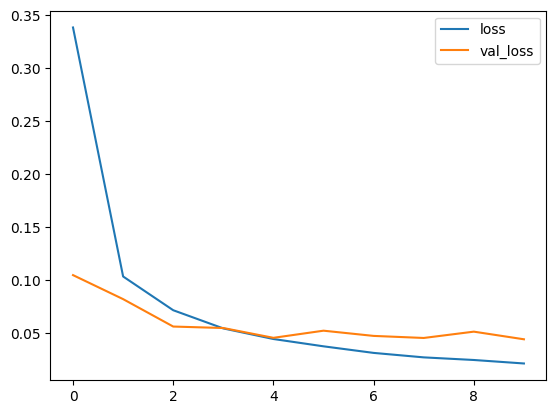

In [5]:
# Plot loss per iteration
import matplotlib.pyplot as plt
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.legend()
plt.show()

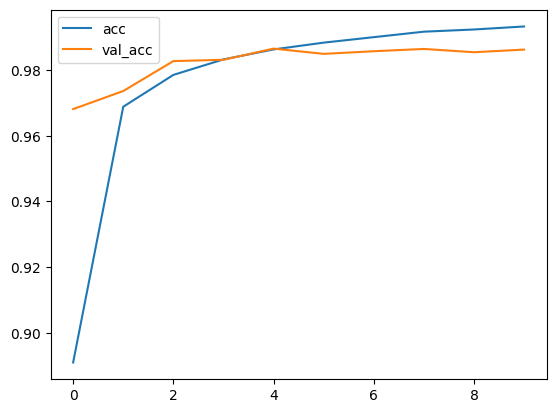

In [6]:
# Plot accuracy per iteration
plt.plot(r.history['accuracy'], label='acc')
plt.plot(r.history['val_accuracy'], label='val_acc')
plt.legend()
plt.show()

In [7]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
y_pred = model.predict(x_test).argmax(axis=1)
cm = confusion_matrix(y_test,y_pred)
print("               Predicted Label")
print(cm)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step
               Predicted Label
[[ 966    0    2    0    1    0    7    2    1    1]
 [   0 1130    1    1    2    0    0    1    0    0]
 [   1    0 1022    2    3    0    1    3    0    0]
 [   0    0    3  993    0    9    0    2    3    0]
 [   0    0    0    0  974    0    1    1    3    3]
 [   0    1    1    3    0  881    2    2    2    0]
 [   0    3    0    0   11    3  939    0    2    0]
 [   0    3    6    3    1    0    0 1012    1    2]
 [   1    0    2    1    0    6    0    3  958    3]
 [   0    0    1    0   11    4    0    3    3  987]]


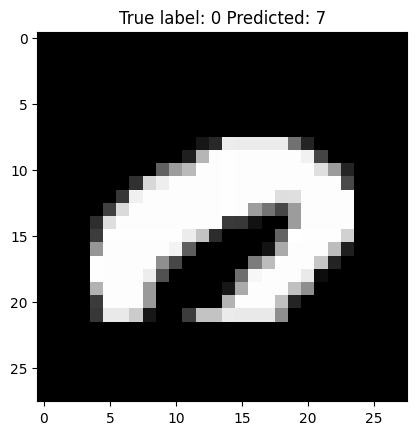

In [8]:
# Show some misclassified examples
misclassified_idx = np.where(y_pred != y_test)[0]
i = np.random.choice(misclassified_idx)
plt.imshow(x_test[i], cmap='gray')
plt.title("True label: %s Predicted: %s" % (y_test[i], y_pred[i]));